# Evaluación Sumativa 3. Modelamiento predictivo integrado
## Framingham Heart Study: riesgo de enfermedad coronaria a 10 años

MCDI501 · Grupo 3 · Integrantes: Felipe Díaz Toro, Pablo Ríos Passteni, Guillermo Subiabre Chacón, Ninoska Yévenes Hernández


## Introducción

La enfermedad coronaria (CHD) es una de las principales causas de muerte en el mundo. El estudio de Framingham siguió a 4.238 personas y registró si presentaron CHD en los 10 años siguientes (`TenYearCHD`). Solo el 15,2 % de los casos la desarrolló, por lo que la clase de interés es minoritaria.

Esta Sumativa 3 integra lo hecho en S1 (exploración y valores faltantes), S2 (validación y remuestreo) y F2 (regresión logística) en un modelo predictivo completo. El trabajo avanza en cuatro frentes:

1. **Datos faltantes.** Imputamos la glucosa (9,16 % de faltantes) mediante regresión lineal múltiple y la comparamos con eliminar los casos y con imputar la mediana.
2. **Tres modelos logísticos** con distintos criterios de selección: variables validadas en S2 (edad y presión sistólica), *stepwise* por AIC y un modelo reducido. Se comparan con odds ratios por desviación estándar y curvas ROC.
3. **Bootstrap** de los coeficientes del mejor modelo, para contrastar sus intervalos de confianza con los tradicionales.
4. **Ponderación de clases** (peso ≈ 3,3 para los casos) para mejorar el recall, que en F2 fue de solo 4,7 %.

### Qué haremos antes de cargar los datos
- **Configuración:** importar las librerías y fijar la semilla (42), la variable objetivo y la paleta de colores.
- **Verificación de integridad:** comprobar que el archivo es el original (huella SHA-256 y forma 4.238 × 16).
- **Primera mirada:** confirmar la prevalencia de CHD y la cantidad de faltantes en la glucosa.

## 0. Configuración y datos

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve)

# Raíz del repo: la carpeta que contiene requirements.txt y redaccion/
ROOT = Path.cwd()
while not ((ROOT / "requirements.txt").exists() and (ROOT / "redaccion").exists()):
    if ROOT == ROOT.parent:
        raise FileNotFoundError("No se encontró la raíz del repositorio")
    ROOT = ROOT.parent

CSV = ROOT / "data" / "raw" / "framingham.csv"
SHA_ESPERADO = "40921748dbdf6587045b9822414199a1ae3349358b63b975ab2208aa3cccc45b"
FORMA_ESPERADA = (4238, 16)
SEED = 42
TARGET = "TenYearCHD"

# Paleta del grupo
NAVY, RED, GREY, BG, OCHRE = "#0d2741", "#ae0000", "#8c8578", "#f6f1ea", "#c0852f"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG,
                     "axes.edgecolor": GREY, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

# Verificación de integridad del dataset
sha = hashlib.sha256(CSV.read_bytes()).hexdigest()
df = pd.read_csv(CSV)
assert sha == SHA_ESPERADO, "El CSV no coincide con el original"
assert df.shape == FORMA_ESPERADA, f"Forma inesperada: {df.shape}"
print("Dataset verificado:", df.shape, "| SHA-256 OK")
print(f"Prevalencia de {TARGET}: {df[TARGET].mean():.2%}")
print(f"Glucosa faltante: {df['glucose'].isna().sum()} ({df['glucose'].isna().mean():.2%})")

Dataset verificado: (4238, 16) | SHA-256 OK
Prevalencia de TenYearCHD: 15.20%
Glucosa faltante: 388 (9.16%)


## 1. Manejo inteligente de datos faltantes

Hasta ahora, en S1, F2 y S2, los datos faltantes se trataron con soluciones rápidas: eliminar filas o rellenar con la mediana. Eran decisiones razonables para avanzar, pero tienen un costo que todavía no medimos. Eliminar filas reduce la muestra y puede sesgarla; la mediana, en cambio, rellena a todos con el mismo valor, aplana la variable y debilita las relaciones que esa variable tiene con las demás.

En Framingham, 582 de las 4.238 personas (13,7 %) tienen al menos un dato faltante. El caso más pesado es la **glucosa**, con 388 registros faltantes (9,16 %), casi diez veces más que cualquier otra variable. Como la glucosa es un predictor clínicamente relevante del riesgo coronario, la forma en que la tratemos puede cambiar las conclusiones del modelo. Por eso concentramos la comparación en ella.

El plan de esta sección tiene tres pasos:
1. **Entender por qué faltan.** No da igual que los datos falten al azar o que falten por una razón ligada a otras variables: de eso depende qué estrategias son defendibles.
2. **Imputar con una regresión lineal múltiple**, que rellena cada valor faltante con una predicción basada en variables relacionadas con la glucosa, en lugar de un valor único para todos.
3. **Comparar tres estrategias** (eliminar, mediana y regresión) para ver con evidencia cuánto cambia la muestra, la distribución de la glucosa y sus relaciones con el resto.

### 1.1 ¿Por qué faltan estos datos?

Antes de rellenar nada conviene preguntarse por qué faltan. Hay tres posibilidades. Si faltan **por puro azar** (MCAR), cualquier método sirve y solo se pierde precisión. Si la falta **depende de otras variables que sí observamos** (MAR), como que en personas sin diabetes se mida menos la glucosa, entonces eliminar filas sesga la muestra, pero imputar usando esas variables es válido. Si la falta depende **del propio valor que no vemos** (MNAR), ningún método estándar lo corrige por completo.

En S1 ya comparamos la falta de glucosa con la enfermedad coronaria, sin encontrar relación significativa (χ² = 1,58; p = 0,21). Eso no prueba nada, porque no descarta que la falta dependa de otras variables. Aquí hacemos la comparación completa: contrastamos, para cada variable sin faltantes, a quienes tienen la glucosa registrada con quienes no, y luego usamos todas juntas en una regresión que intenta predecir quién tendrá la glucosa faltante.

Un punto de honestidad metodológica: estos tests solo pueden **rechazar** MCAR. Ninguno puede demostrar MAR, porque MNAR depende de lo que no observamos. Lo que haremos es adoptar MAR como supuesto de trabajo, explicitarlo y justificar por qué es razonable.

In [2]:
from scipy import stats

faltantes = (df.isna().sum().to_frame("n_faltantes")
               .assign(pct=lambda d: (d.n_faltantes / len(df) * 100).round(2))
               .query("n_faltantes > 0")
               .sort_values("n_faltantes", ascending=False))
display(faltantes)
print("Filas con algún faltante:", df.isna().any(axis=1).sum())

,n_faltantes,pct
glucose,388,9.16
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


Filas con algún faltante: 582


In [3]:
df["glu_falta"] = df["glucose"].isna().astype(int)
completas = [c for c in df.columns
             if df[c].notna().all() and c not in ("glu_falta", TARGET)]
binarias = [c for c in completas if df[c].nunique() == 2]
continuas = [c for c in completas if c not in binarias]

filas = []
for c in continuas:                       # t de Welch
    a, b = df.loc[df.glu_falta == 1, c], df.loc[df.glu_falta == 0, c]
    filas.append((c, f"{a.mean():.2f}", f"{b.mean():.2f}", stats.ttest_ind(a, b, equal_var=False).pvalue))
for c in binarias:                        # chi-cuadrado
    tab = pd.crosstab(df[c], df.glu_falta)
    filas.append((c, f"{df.loc[df.glu_falta == 1, c].mean():.1%}",
                  f"{df.loc[df.glu_falta == 0, c].mean():.1%}", stats.chi2_contingency(tab)[1]))

comp = pd.DataFrame(filas, columns=["variable", "glucosa faltante", "glucosa observada", "p"])
comp["p"] = comp["p"].round(4)
display(comp.sort_values("p"))

,variable,glucosa faltante,glucosa observada,p
3,male,29.6%,44.3%,0.0000
7,diabetes,1.0%,2.7%,0.0652
0,age,49.00,49.64,0.1480
4,currentSmoker,52.8%,49.1%,0.1731
1,sysBP,131.39,132.45,0.3456
6,prevalentHyp,28.9%,31.3%,0.3581
2,diaBP,82.54,82.93,0.5243
5,prevalentStroke,0.3%,0.6%,0.5832


In [4]:
X = sm.add_constant(df[completas].astype(float))
m_falta = sm.Logit(df["glu_falta"], X).fit(disp=0)
lr_p = m_falta.llr_pvalue
print(f"Pseudo R² = {m_falta.prsquared:.3f} | test de razón de verosimilitud p = {lr_p:.4g}")
print(m_falta.summary2().tables[1].round(4)[["Coef.", "P>|z|"]])

# Solo diagnóstico: la tasa de CHD según faltante (el target NO se usa para imputar)
print(df.groupby("glu_falta")[TARGET].mean().round(4))

Pseudo R² = 0.017 | test de razón de verosimilitud p = 3.345e-07
                  Coef.   P>|z|
const           -2.1207  0.0002
male            -0.6991  0.0000
age             -0.0036  0.6192
currentSmoker    0.2547  0.0235
prevalentStroke -0.7984  0.4366
prevalentHyp    -0.0381  0.8208
diabetes        -0.8834  0.0867
sysBP           -0.0030  0.5273
diaBP            0.0068  0.3825
glu_falta
0    0.1543
1    0.1289
Name: TenYearCHD, dtype: float64


### Qué vemos

De las siete variables con faltantes, la glucosa es la más afectada (388 registros, 9,16 %), muy por encima de educación (2,48 %), medicación antihipertensiva (1,25 %) y el resto (menos del 1,2 %). En total, 582 personas tienen al menos un dato faltante.

Al comparar a quienes tienen la glucosa registrada con quienes no, **la única diferencia clara es el sexo**: entre los registros sin glucosa hay un 29,6 % de hombres, contra un 44,3 % entre los que sí la tienen (p < 0,0001). Es decir, la glucosa falta con más frecuencia en mujeres. La regresión logística confirma este patrón: a igualdad del resto de las variables, ser hombre reduce a la mitad aproximadamente la probabilidad de que falte (OR ≈ 0,50). El tabaquismo actual muestra un efecto menor (OR ≈ 1,29; p = 0,024), que preferimos no sobreinterpretar porque surge de varias comparaciones simultáneas. La diabetes presenta una diferencia en la dirección esperada (1,0 % vs 2,7 %), pero no alcanza significancia (p = 0,065) y se apoya en muy pocos casos. Edad, presión arterial, hipertensión y antecedente de ACV no se diferencian.

Estas diferencias son pequeñas en conjunto: las variables observadas explican muy poco de quién tiene la glucosa faltante (pseudo R² = 0,017). Tampoco hay relación clara con el desenlace: la tasa de enfermedad coronaria es de 12,9 % entre los faltantes y 15,4 % entre los observados, coherente con lo hallado en S1 (p = 0,21).

**Supuesto de trabajo.** La evidencia permite **rechazar MCAR**, porque la falta de glucosa depende del sexo. Adoptamos **MAR** como supuesto: la probabilidad de que falte la glucosa depende de variables que sí observamos, principalmente el sexo. Esto no puede demostrarse con los datos, ya que un mecanismo MNAR (la glucosa falta por su propio valor) es indistinguible desde lo observado. Lo que sí implica es una decisión práctica: **el sexo debe incluirse como predictor en la imputación por regresión**, y eliminar casos sería menos defendible, pues dejaría la muestra con menos mujeres de las que tenía.

### 1.2 Imputación mediante regresión lineal múltiple

Imputar con la mediana le da a las 388 personas el mismo valor de glucosa, sin importar si son hombres o mujeres, jóvenes o mayores, diabéticos o no. La imputación por regresión intenta algo mejor: **predecir la glucosa de cada persona a partir de otras variables que sí conocemos**, de modo que el valor rellenado refleje su perfil. Para que el método sea honesto con la evaluación posterior, seguimos tres reglas. Primero, **partimos los datos antes de imputar** (70 % entrenamiento, 30 % prueba, estratificado por `TenYearCHD`), y el modelo de imputación se ajusta solo con el entrenamiento; así el conjunto de prueba no influye en nada de lo que se aprende. Segundo, los predictores se eligen por criterio y no por intuición: entre las variables **sin faltantes**, tomamos las que más se correlacionan con la glucosa en S1, dando prioridad a las que S2 validó como estables (edad y presión sistólica), y sumamos el sexo, que en la sección anterior resultó ser lo que explica la falta. Tercero, **la variable objetivo no se usa jamás** como predictor ni se imputa: haría que el modelo supiera la respuesta que después debe predecir.

In [ ]:
# Partición 70/30 estratificada, ANTES de imputar (misma semilla que F2)
train, test = train_test_split(df.drop(columns="glu_falta"), test_size=0.30,
                               stratify=df[TARGET], random_state=SEED)
print(f"train = {len(train)} | test = {len(test)}")
print(f"Prevalencia CHD: train {train[TARGET].mean():.2%} | test {test[TARGET].mean():.2%}")

# Candidatos a predictor: variables SIN faltantes (se excluye el target)
candidatos = [c for c in df.columns
              if df[c].notna().all() and c not in (TARGET, "glu_falta")]

# Correlación con la glucosa, solo casos completos del train
tr_glu = train.dropna(subset=["glucose"])
print(f"Casos completos de glucosa en train: {len(tr_glu)}")
corr = pd.DataFrame({
    "pearson": tr_glu[candidatos].corrwith(tr_glu["glucose"]),
    "spearman": tr_glu[candidatos].corrwith(tr_glu["glucose"], method="spearman"),
}).round(3)
corr["|pearson|"] = corr["pearson"].abs()
display(corr.sort_values("|pearson|", ascending=False).drop(columns="|pearson|"))


train = 2966 | test = 1272
Prevalencia CHD: train 15.21% | test 15.17%
Casos completos de glucosa en train: 2680


,pearson,spearman
diabetes,0.635,0.237
sysBP,0.135,0.109
age,0.112,0.108
prevalentHyp,0.077,0.067
currentSmoker,-0.063,-0.081
diaBP,0.054,0.034
prevalentStroke,0.035,0.022
male,0.013,-0.016


**Partición y elección de predictores.** La partición estratificada dejó 2.966 personas en entrenamiento y 1.272 en prueba, con la misma prevalencia de enfermedad coronaria en ambas (15,21 % y 15,17 %). De las 2.966 de entrenamiento, 2.680 tienen la glucosa registrada y son las que usamos para ajustar el modelo de imputación.

Entre las variables sin faltantes, **la diabetes es, por lejos, la que más se asocia con la glucosa** (r = 0,635), seguida de la presión sistólica (0,135) y la edad (0,112); el resto queda bajo 0,08. La distancia entre la correlación de Pearson de la diabetes (0,635) y la de Spearman (0,237) indica que esa relación se sostiene en pocos valores muy altos, de personas diabéticas, y no en un aumento gradual de la glucosa. Esto lo tendremos presente al revisar los residuos.

Los predictores elegidos son cinco: **diabetes, presión sistólica y edad** (por correlación, y las dos últimas por estar validadas en S2), **sexo** (porque explica la falta de glucosa según 1.1, aunque casi no se correlaciona con ella) y **tabaquismo actual** (efecto débil sobre la falta). La presión diastólica y la hipertensión quedan fuera porque son redundantes con la sistólica, y el antecedente de ACV por su correlación casi nula.

n = 2680 | R² = 0.408 | R² ajustado = 0.407 | RMSE = 18.37 mg/dL


,Coef.,Std.Err.,P>|t|
const,68.897,2.706,0.000
diabetes,89.302,2.143,0.000
sysBP,0.063,0.018,0.000
age,0.057,0.046,0.212
male,-0.178,0.732,0.808
currentSmoker,-1.018,0.746,0.172


RMSE validación cruzada -> regresión: 18.59 | mediana: 24.19
Asimetría de los residuos: 2.14


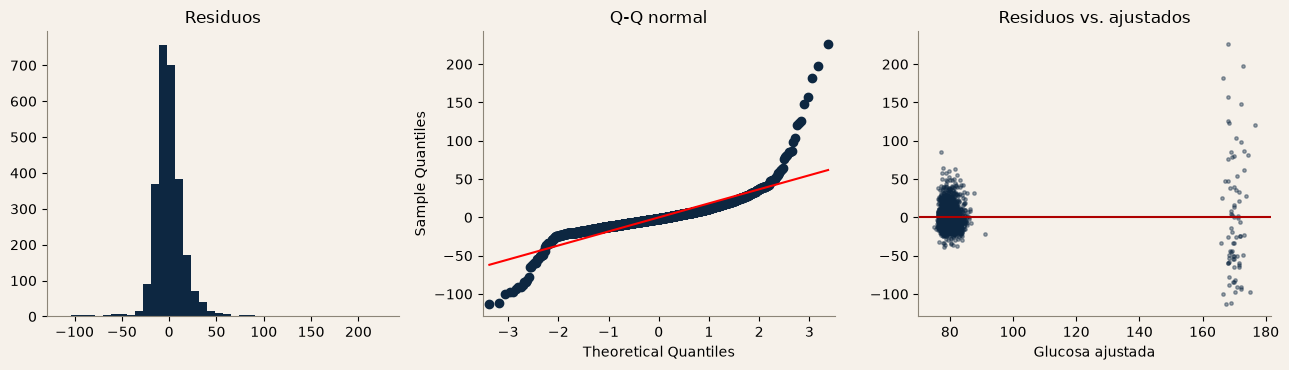

In [6]:
from sklearn.model_selection import KFold

pred = ["diabetes", "sysBP", "age", "male", "currentSmoker"]
y = tr_glu["glucose"]
X = sm.add_constant(tr_glu[pred].astype(float))
ols = sm.OLS(y, X).fit()

print(f"n = {int(ols.nobs)} | R² = {ols.rsquared:.3f} | R² ajustado = {ols.rsquared_adj:.3f} "
      f"| RMSE = {np.sqrt(ols.mse_resid):.2f} mg/dL")
display(ols.summary2().tables[1].round(3)[["Coef.", "Std.Err.", "P>|t|"]])

# Desempeño fuera de muestra (validación cruzada 5 pliegues) vs imputar la mediana
err_reg, err_med = [], []
for tr_i, va_i in KFold(5, shuffle=True, random_state=SEED).split(tr_glu):
    m = LinearRegression().fit(tr_glu.iloc[tr_i][pred], y.iloc[tr_i])
    err_reg.append(y.iloc[va_i] - m.predict(tr_glu.iloc[va_i][pred]))
    err_med.append(y.iloc[va_i] - y.iloc[tr_i].median())
rmse = lambda e: np.sqrt(np.mean(np.concatenate(e) ** 2))
print(f"RMSE validación cruzada -> regresión: {rmse(err_reg):.2f} | mediana: {rmse(err_med):.2f}")

# Supuestos: residuos
res, ajust = ols.resid, ols.fittedvalues
print(f"Asimetría de los residuos: {stats.skew(res):.2f}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].hist(res, bins=40, color=NAVY); ax[0].set_title("Residuos")
sm.qqplot(res, line="s", ax=ax[1], markerfacecolor=NAVY, markeredgecolor=NAVY)
ax[1].set_title("Q-Q normal")
ax[2].scatter(ajust, res, s=6, alpha=.4, color=NAVY); ax[2].axhline(0, color=RED)
ax[2].set_title("Residuos vs. ajustados"); ax[2].set_xlabel("Glucosa ajustada")
plt.tight_layout(); plt.show()

Con el modelo ajustado, imputamos la glucosa en el entrenamiento y en la prueba **usando siempre el modelo del entrenamiento**. Generamos dos versiones. En la primera, cada valor faltante recibe la **predicción** de la regresión. En la segunda, a esa predicción se le suma un **residuo tomado al azar** de los residuos observados, de modo que los valores imputados conserven la dispersión real de la glucosa y no se amontonen en torno a un único valor. A ambas las acotamos entre el mínimo y el máximo observados en el entrenamiento, para no generar glucosas imposibles. También dejamos lista la imputación por mediana, que usaremos como comparación en la sección 1.3.

In [7]:
rng = np.random.default_rng(SEED)
modelo_imp = LinearRegression().fit(tr_glu[pred], y)      # mismo ajuste que el OLS
residuos = (y - modelo_imp.predict(tr_glu[pred])).to_numpy()
g_min, g_max, g_mediana = y.min(), y.max(), y.median()

def imputar(d):
    d = d.copy()
    falta = d["glucose"].isna()
    p = modelo_imp.predict(d.loc[falta, pred])
    d["glu_mediana"] = d["glucose"].fillna(g_mediana)
    d["glu_reg"] = d["glucose"]
    d.loc[falta, "glu_reg"] = np.clip(p, g_min, g_max)
    d["glu_reg_ruido"] = d["glucose"]
    d.loc[falta, "glu_reg_ruido"] = np.clip(p + rng.choice(residuos, falta.sum()), g_min, g_max)
    d["glu_imputada"] = falta
    return d

train_i, test_i = imputar(train), imputar(test)

print(f"Valores imputados: train {train_i.glu_imputada.sum()} ({train_i.glu_imputada.mean():.2%}) | "
      f"test {test_i.glu_imputada.sum()} ({test_i.glu_imputada.mean():.2%})")
print(f"Total: {train_i.glu_imputada.sum() + test_i.glu_imputada.sum()} (esperado: 388)")

# ¿Cómo quedan los valores imputados frente a los observados? (train)
obs = train_i.loc[~train_i.glu_imputada, "glucose"]
resumen = pd.DataFrame({
    "observada": obs.describe(),
    "mediana": train_i.loc[train_i.glu_imputada, "glu_mediana"].describe(),
    "regresión": train_i.loc[train_i.glu_imputada, "glu_reg"].describe(),
    "regresión + ruido": train_i.loc[train_i.glu_imputada, "glu_reg_ruido"].describe(),
}).round(1)
display(resumen)

Valores imputados: train 286 (9.64%) | test 102 (8.02%)
Total: 388 (esperado: 388)


,observada,mediana,regresión,regresión + ruido
count,2680.0,286.0,286.0,286.0
mean,82.1,78.0,80.3,80.3
std,23.9,0.0,9.3,22.9
min,40.0,78.0,76.2,40.0
25%,71.0,78.0,78.1,69.4
50%,78.0,78.0,79.2,77.1
75%,87.0,78.0,80.5,85.0
max,394.0,78.0,172.1,275.9


### Qué vemos

El modelo de imputación se ajustó con las 2.680 personas del entrenamiento que tienen glucosa registrada y explica el 41 % de su variación (R² = 0,408; error típico de 18,4 mg/dL). En validación cruzada, su error (18,6 mg/dL) es un 23 % menor que el de imputar la mediana (24,2 mg/dL), sin señales de sobreajuste. Sin embargo, esa mejora proviene casi por completo de la **diabetes**, que suma unos 89 mg/dL a la glucosa predicha; la presión sistólica aporta un efecto significativo pero mínimo (0,6 mg/dL por cada 10 mmHg), y la edad, el sexo y el tabaquismo no son significativos. En la práctica, el modelo distingue a las personas con diabetes del resto.

Los supuestos del modelo lineal se cumplen solo en parte: los residuos son asimétricos (asimetría = 2,14), tienen colas pesadas y su varianza es mucho mayor entre los diabéticos que entre los demás. Esto resta confiabilidad a los valores p de la tabla de coeficientes, pero no invalida el uso del modelo para imputar, ya que lo que necesitamos de él son predicciones promedio.

Se imputaron 388 valores de glucosa: 286 en el entrenamiento (9,64 %) y 102 en la prueba (8,02 %). Como casi todas esas personas no tienen diabetes, la regresión les asigna valores cercanos a 80 mg/dL (media 80,3; desviación estándar 9,3), de modo que la glucosa imputada es **mucho menos variable que la real** (desviación estándar 23,9). Es una mejora frente a la mediana, que repite un mismo valor (78,0) en todos, pero sigue siendo una compresión. La versión con ruido residual recupera la dispersión (22,9), aunque la exagera en las colas (máximo 275,9), porque sortea residuos que incluyen los de las personas diabéticas. Ambas versiones se comparan en la sección siguiente.

### 1.3 ¿Importa cómo tratemos la glucosa faltante?

Ya tenemos cuatro formas de resolver el problema: **eliminar** a las personas sin glucosa, imputar la **mediana**, imputar con la **regresión** e imputar con la regresión más **ruido residual**. Antes de elegir una para el resto del trabajo, las miramos con tres preguntas:

1. **¿Cuánta muestra y qué tipo de muestra queda?** Eliminar filas no solo achica el dataset: como la glucosa falta más en mujeres, también puede cambiar su composición.
2. **¿Qué le pasa a la distribución de la glucosa?** Una buena imputación no debería inventar una glucosa más uniforme (ni más extrema) que la real.
3. **¿Se conservan las relaciones que vimos en S1?** Lo que más importa es que la glucosa siga relacionada con la diabetes, la presión y la edad como antes. Una imputación que las diluye debilita los modelos que vienen después.

Todo se calcula sobre el conjunto de entrenamiento. La referencia para las relaciones es la glucosa realmente observada.

,n,% del train,% hombres,edad media,prevalencia CHD
Eliminación,2680,90.4%,44.4%,49.8,15.52%
Mediana,2966,100.0%,43.3%,49.7,15.21%
Regresión,2966,100.0%,43.3%,49.7,15.21%
Regresión + ruido,2966,100.0%,43.3%,49.7,15.21%


,media,desv. est.,asimetría,mediana,P95,máx
Eliminación,82.07,23.85,5.74,78.00,109.00,394.0
Mediana,81.68,22.71,6.07,78.00,107.00,394.0
Regresión,81.90,22.86,5.97,78.21,107.75,394.0
Regresión + ruido,81.90,23.77,5.65,78.00,108.00,394.0


,diabetes,sysBP,age,TenYearCHD
Eliminación,0.635,0.135,0.112,0.120
Mediana,0.623,0.129,0.108,0.116
Regresión,0.642,0.137,0.110,0.121
Regresión + ruido,0.615,0.135,0.098,0.114


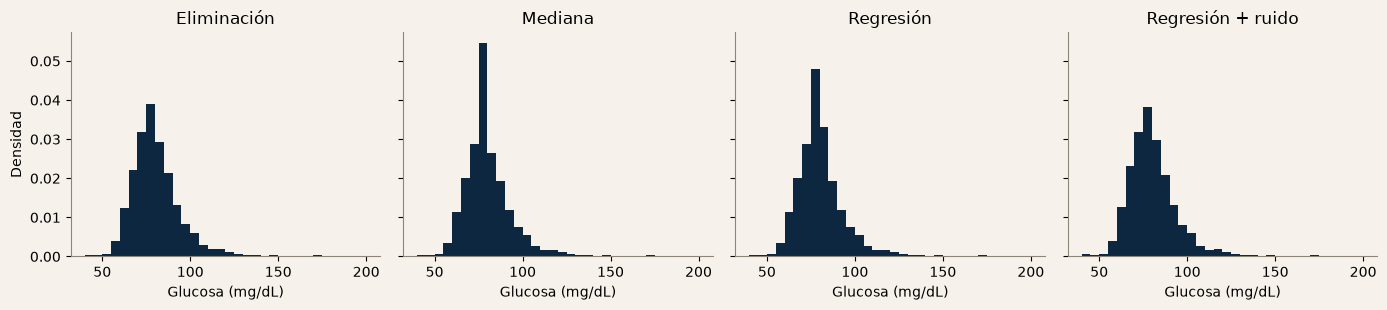

In [8]:
tr = train_i
elim = tr[~tr.glu_imputada]            # eliminación: solo casos con glucosa observada
estrategias = {
    "Eliminación":       (elim, elim["glucose"]),
    "Mediana":           (tr, tr["glu_mediana"]),
    "Regresión":         (tr, tr["glu_reg"]),
    "Regresión + ruido": (tr, tr["glu_reg_ruido"]),
}

# 1) Tamaño y composición de la muestra
t1 = pd.DataFrame({
    nom: {"n": len(d), "% del train": f"{len(d)/len(tr):.1%}",
          "% hombres": f"{d['male'].mean():.1%}",
          "edad media": f"{d['age'].mean():.1f}",
          "prevalencia CHD": f"{d[TARGET].mean():.2%}"}
    for nom, (d, g) in estrategias.items()}).T
display(t1)

# 2) Distribución de la glucosa
t2 = pd.DataFrame({
    nom: {"media": g.mean(), "desv. est.": g.std(), "asimetría": stats.skew(g),
          "mediana": g.median(), "P95": g.quantile(.95), "máx": g.max()}
    for nom, (d, g) in estrategias.items()}).T.round(2)
display(t2)

# 3) Relaciones con la glucosa (correlación de Pearson)
vars_rel = ["diabetes", "sysBP", "age", TARGET]
t3 = pd.DataFrame({
    nom: {v: d[v].corr(g) for v in vars_rel}
    for nom, (d, g) in estrategias.items()}).T.round(3)
display(t3)

# Gráfico: distribución de la glucosa por estrategia
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for a, (nom, (d, g)) in zip(ax, estrategias.items()):
    a.hist(g, bins=np.arange(40, 205, 5), color=NAVY, density=True)
    a.set_title(nom); a.set_xlabel("Glucosa (mg/dL)")
ax[0].set_ylabel("Densidad")
plt.tight_layout(); plt.show()

### Qué vemos

Como solo el 9,6 % de las glucosas del entrenamiento fue imputado, las diferencias entre estrategias son pequeñas, pero hay un patrón claro.

- **Muestra:** eliminar deja 2.680 de 2.966 personas (90,4 %) y cambia levemente su composición (hombres de 43,3 % a 44,4 %), coherente con que la glucosa falta más en mujeres. Las imputaciones conservan a todos.
- **Distribución:** la mediana crea un pico artificial en 78 mg/dL (desviación estándar 22,71 frente a 23,85 real). La regresión mejora algo (22,86), y la regresión con ruido es la más fiel (23,77).
- **Relaciones:** la regresión conserva las correlaciones de S1 (diferencias menores a 0,01), la mediana las debilita levemente y la versión con ruido es la que más las diluye. La correlación con la enfermedad coronaria, que no entró en la imputación, se mantiene (0,121 frente a 0,120).

**Estrategia elegida:** imputación por regresión determinista. Conserva toda la muestra, preserva las relaciones de S1 y no depende del azar. La eliminación queda como referencia, y la mediana y la regresión con ruido como análisis de sensibilidad en la sección 3.

## 2. Clasificación mediante regresión logística (30 pts + 30 pts de bootstrap)
### 2.1 Preparación de datos informada por S1
TODO: dataset con la estrategia elegida, partición 70/30 estratificada, tratamiento justificado de los outliers de S1 (tope de glucosa de S2), estandarización y codificación de categóricas. Imputar y estandarizar con parámetros del train.

In [ ]:
# TODO: partición, outliers, estandarización

### 2.2 Tres modelos logísticos


In [ ]:
# TODO: modelo 1 (S1/S2)

In [ ]:
# TODO: modelo 2 (stepwise)

In [ ]:
# TODO: modelo 3 (AIC/BIC o reducido)

### 2.3 Ponderación de clases
TODO: ponderar las clases con peso ≈ 3,3 para los casos de CHD (`class_weight='balanced'`; con statsmodels, mediante `freq_weights` o con scikit-learn) y documentar el efecto en recall, matriz de confusión y AUC frente a F2 (recall = 4,7 % con umbral 0,5).

In [ ]:
# TODO: modelos con ponderación de clase y/o umbral ajustado

### 2.4 Evaluación de desempeño y selección del modelo final
TODO: para los tres modelos, matriz de confusión (train y test), accuracy, precision, **recall** y F1, y **AUC**, con las curvas ROC de los tres en un mismo gráfico. Elegir y justificar el modelo final.

In [ ]:
# TODO: métricas, matrices de confusión y ROC comparada

### 2.5 Estabilidad mediante bootstrap (30 pts)
TODO: bootstrap (como en S2, ≥ 1.000 remuestras; en S2 usamos 10.000) al mejor modelo: IC al 95 % de coeficientes y odds ratios, comparados con los IC tradicionales; identificar parámetros inestables.

In [ ]:
# TODO: bootstrap de coeficientes y odds ratios

### 2.6 Diagnóstico de supuestos
TODO: **VIF** (la sistólica llega a ~3,7 con la diastólica y la hipertensión: bajo el umbral de 5, pero conviene quedarse con una), linealidad en el logit, observaciones influyentes (las de S2: filas 481, 2909, 3160, 2197 y 781) y residuos.

In [ ]:
# TODO: VIF, linealidad en el logit, influyentes, residuos

## 3. Análisis comparativo del impacto de la imputación (9 pts)
TODO: ajustar el modelo final con los tres datasets (eliminación, mediana, regresión) y comparar tamaño muestral, coeficientes, IC, AUC y accuracy en test; analizar si la estrategia de imputación cambia las conclusiones y formular recomendaciones.

In [ ]:
# TODO: modelo final con los tres datasets y tabla comparativa

## 4. Síntesis integrada (parte del informe final, 9 pts)
TODO: cómo cada fase (S1, S2, S3) informa a la siguiente; resultados principales, limitaciones y recomendaciones.

## Checklist de entrega
- [ ] Ejecuta sin errores de principio a fin y con salidas visibles
- [ ] Faltantes: referencia a S1, imputación por regresión y comparación de tres estrategias
- [ ] Tres modelos logísticos con odds ratios y variables justificadas con S1/S2
- [ ] Ponderación de clase / umbral y efecto sobre el recall
- [ ] Matrices de confusión (train y test), métricas y ROC comparada
- [ ] Bootstrap de coeficientes y odds ratios con IC al 95 %
- [ ] VIF, linealidad en el logit, influyentes y residuos
- [ ] Comparación del modelo final con los tres datasets
- [ ] Informe final (máx. 10 págs.) y presentación (10 min)
- [ ] Semilla fijada (SEED = 42)